## **新型コロナウイルススパイク蛋白質の相互作用解析**
----


新型コロナウイルス(SARS-Cov-2)のスパイク蛋白質とヒトACE2受容体の複合体の分子動力学シミュレーションのデータを用いてランダムフォレストの学習を行う [1]。 学習後、SARS-Cov-2とSARS-Cov-1(旧型コロナ)を比較することで、スパイク蛋白質とACE2間の相互作用において重要性が高い残基ペアを見つける。

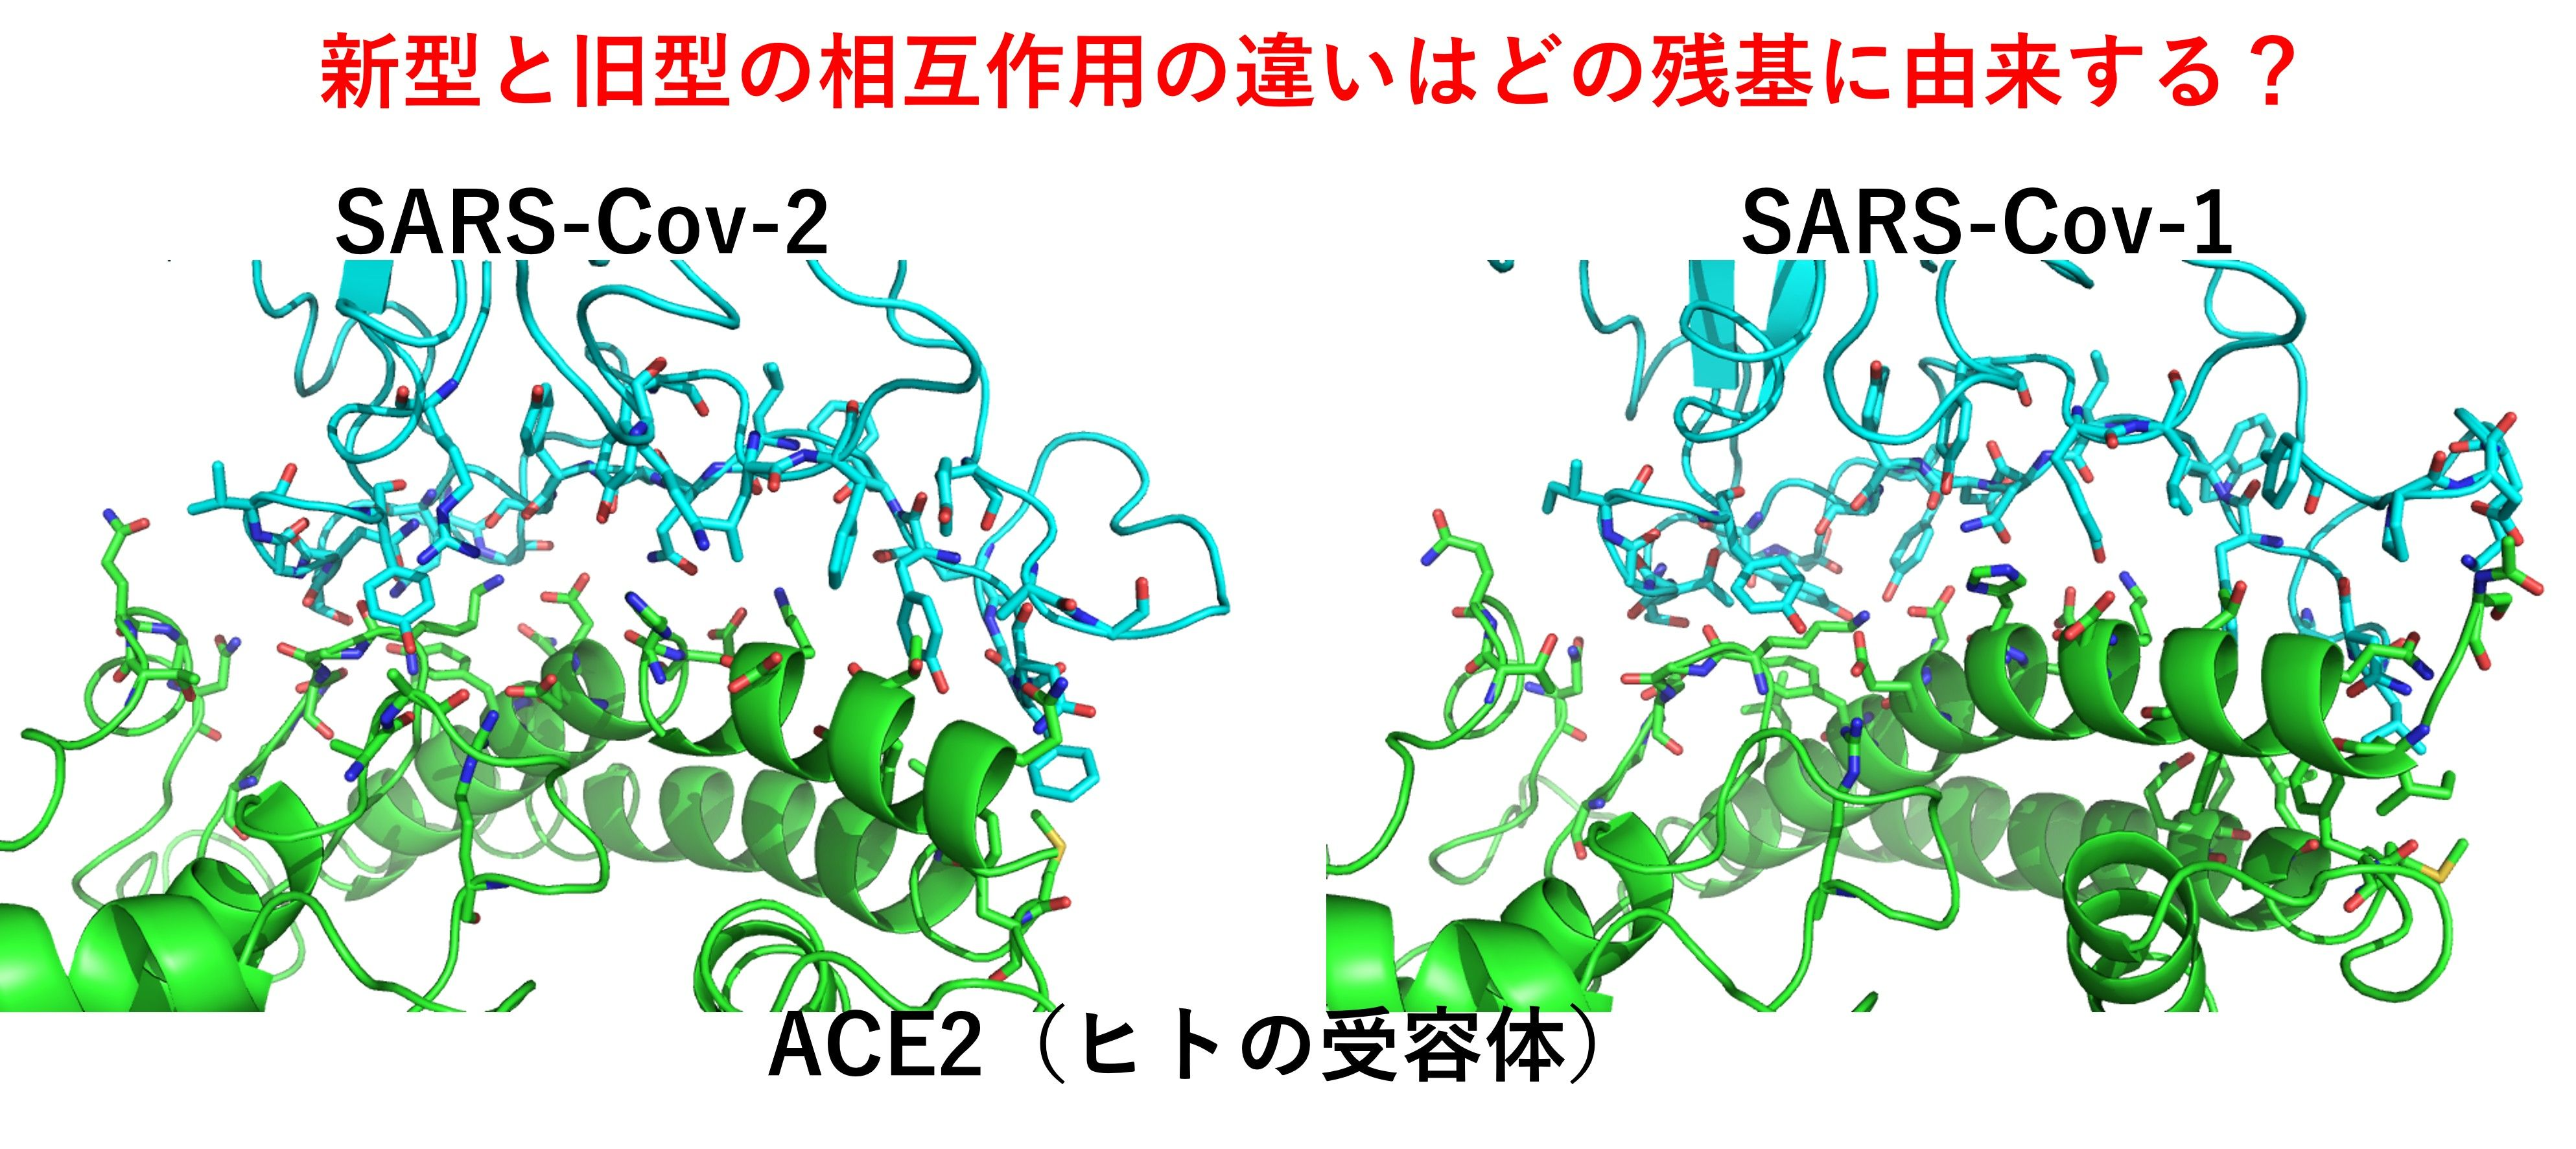

残基間の距離が近い　→　相互作用が強い

残基間の距離が遠い　→　相互作用が弱い

と考え、スパイク蛋白質のレセプター結合ドメイン（RBD）とACE2の残基間距離を学習データとして用いる。

# 学習データの準備

In [ ]:
# ライブラリーの読み込み
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import recall_score,accuracy_score,confusion_matrix, f1_score, precision_score, auc,roc_auc_score,roc_curve, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.model_selection import GridSearchCV,train_test_split
from sklearn.metrics import (recall_score,accuracy_score,confusion_matrix, f1_score, precision_score, auc,roc_auc_score,roc_curve, precision_recall_curve,classification_report)
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# データセットの読み込み
df = pd.read_csv("/content/drive/MyDrive/taiken/sars_tutorial/sars.csv", header=None)
print(df)

行方向がシミュレーションのスナップショットに対応し、列方向が各スナップショットにおける残基ペア(4886ペア)の距離に対応する。

このデータセットではCov-1とCov-2のスナップショットを1つにまとめており、0～1999行がCov-1のスナップショット、2000～3999行がCov-2のスナップショットになっていている。

In [ ]:
# ACE2とcovの残基ペア情報を読み込む
cov1_pairs = np.loadtxt ("/content/drive/MyDrive/taiken/sars_tutorial/cov1_pairs.txt", dtype = int )
cov2_pairs = np.loadtxt ("/content/drive/MyDrive/taiken/sars_tutorial/cov2_pairs.txt", dtype = int )
print(cov1_pairs)
print(cov2_pairs)

dfの残基ペア(0～4885)が実際にACE2のどの残基とCovのどの残基に対応するかを表している。

例えば、dfでの2番目の残基ペアは、cov1_pairsからACE2の21番目の残基とCov-1の404番目の残基に対応することがわかる。

一方、同じ残基ペアは、cov2_pairsからはACE2の21番目の残基とCov-2の417番目の残基に対応する。

どの行（スナップショット）の残基間相互作用がCov-1かCov-2かを分類できるように学習させたい。

そのために、dfの最終列に正解ラベルを追加する。

正解ラベルはCov-1は0、Cov-2は1とする。

In [ ]:
# covという名前の列を追加し、Cov-1では0、Cov-2では1とする
df['cov'] = 'cov'
df.iloc[0:2000, -1] = 0
df.iloc[2000:4000, -1] = 1

In [ ]:
df.head()

In [ ]:
df.tail()

4886個の残基ペアのうち互いに相関が大きいものが混じっていることがある。

例えば、残基ペアiの値が大きいとき、残基ペアjの値も大きくなり、逆に残基ペアiの値が小さいとき、残基ペアjの値も小さくなっているとき、iとjは相関が大きい。

相関が大きい残基ペアは傾向が似ているため、同じ情報をもっていると解釈できる。
重複した情報をデータに含めると偏りが出ることがあるため、取り除く必要がある。
また、特徴量の数を減らすことで計算が速くすることができる。

In [ ]:
# 処理する前の特徴量
features_pre = df.iloc[:,:-1]
print(features_pre.shape[1]+1)

処理する前の元データの相関行列を計算し、図示する。



In [ ]:
# 相関行列を計算
corr_matrix_before = features_pre.corr(min_periods=1).abs()

# 相関行列を図示
fig, ax = plt.subplots(1, figsize=(4,4), tight_layout=True)
im = plt.imshow(corr_matrix_before, interpolation='nearest', origin='lower')
cbar = ax.figure.colorbar(im, shrink=0.7, label='Absolute correlation')

相関(Absolute correlation)が大きい程、色が黄色に近づくようになっている。

黄色い場所がいくつかあることが確認できる。

ここでは、相関が0.9以上のものを取り除くことにする。

In [ ]:
# 相関が0.9以上のものを取り除くため、カットオフを0.9とする
cutoff = 0.9

# 相関が0.9以上のものを取り除いたデータセットを作成
upper = corr_matrix_before.where(np.triu(np.ones(corr_matrix_before.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > cutoff)]
df_dropped = df.drop(columns = to_drop)

# 削減後の特徴量
print(df_dropped.shape[1]+1)

処理後のデータの相関行列を計算し、図示する。

黄色い部分が減っていることが確認できる。

In [ ]:
features_postcorr = df_dropped.iloc[:,:-1]
corr_matrix_after = features_postcorr.corr(min_periods=1).abs()

fig, ax = plt.subplots(1, figsize=(4,4), tight_layout=True)
im = plt.imshow(corr_matrix_after, interpolation='nearest', origin='lower')
cbar = ax.figure.colorbar(im, shrink=0.7, label='Absolute correlation')

# 残基の重要度を求める関数の作成

ランダムフォレストでは残基ペアごとの重要度が求まる。

それを基に、残基ペアを構成するACE2残基とCov残基のそれぞれの重要度を割り当てる。
例えば、残基ペア（A, B）の重要度が0.3である場合、残基Aと残基Bに重要度0.3を割り当てる。

異なる残基ペアには同じ残基が含まれることがあるが、その場合は重複している残基は重要度を足したものにする。
例えば、残基ペア（A1, B）の重要度が0.2で、残基ペア（A2, B）の重要度が0.3の場合は、残基Bの重要度は 0.2 + 0.3 = 0.5 となる。

以下のsum_elements関数は重複する残基の重要度を足し合わせることで、各残基の重要度を計算する。
最後に、重要度が最大の残基を探し、その重要度で各残基の重要度を割ることで、全体を1に規格化する。

In [ ]:
def sum_elements(i_array):
    # 残基番号が重複しないようにi_arrayに入っている残基番号を取り出す
    resid = []
    for i in i_array:
        if i[0] not in resid:
            resid.append(i[0])
    import_sum = []
    # 残基ごとに重要度を足していく
    for i in resid:
        su = 0
        for j in i_array:
            if j[0] == i:
                su = su + j[1]
        import_sum.append([i,su])
    import_sum = np.array(import_sum)
    xmax, ymax = import_sum.max(axis=0)
    # 重要度が最大の残基の重要度で全体を規格化する
    import_sum[:,1] /= ymax
    import_sum = import_sum[import_sum[:,0].argsort()]
    return import_sum

# ランダムフォレストの学習

Cov-2とACE2の相互作用において重要度が高い残基を保存する用のデータフレームを用意しておく。

Cov-2は残基 336-519、Cov-1は残基 323-503、ACE2は残基 21-616。

In [ ]:
RF_impo_res_cov2 = pd.DataFrame(columns = range(336,519))
RF_impo_res_cov1 = pd.DataFrame(columns = range(323,503))
RF_impo_res_ace = pd.DataFrame(columns = range(21,616))

ランダムフォレストのハイパーパラメータを設定する。

ハイパーパラメータは人間が設定するもので、通常は複数の組み合わせを試して最も良いものを探す必要がある。

In [ ]:
RF_tuned_params = {'max_depth': 60, #Maximum depth of tree
                   'max_features': 50, #Number of features to consider for best split
                   'min_samples_leaf': 1, #Minimum number of samples required to be at a leaf node
                   'n_estimators': 500,  #Number of trees in the forest
                   'n_jobs': -1, #Number of jobs to run in parallel (-1 = all processors)
                   'random_state': 42
                  }

RF = RandomForestClassifier().set_params(**RF_tuned_params)

20回繰り返して各残基の重要度の平均値を求める。

In [ ]:
# 正解率を保存する配列を作成
acc = []

X = df_dropped.iloc[:,:-1]
y = df_dropped['cov']

X, y = X.to_numpy(), y.to_numpy()
num_features = X.shape[1]

# 20回繰り返す
for run in range(20):

    df_rf_coef = pd.DataFrame(columns = df_dropped.columns[:-1])

    # データをランダムにシャッフルし、学習用とテスト用に8:2で分割する
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.20, random_state = 43)

    y_train = y_train.astype(int)

    # 学習データを用いてランダムフォレストを学習
    RF.fit(X_train, y_train)

    # テストデータを用いて予測
    y_pred = RF.predict(X_test)

    y_test = y_test.astype(int)
    y_pred = y_pred.astype(int)

    # 正解率を計算し、accに保存
    acc.append(accuracy_score(y_test, y_pred))

    # 各残基ペアの重要度を求める
    new_data = pd.DataFrame(np.reshape(RF.feature_importances_, (1,num_features)), columns = df_dropped.columns[:-1])
    df_rf_coef = pd.concat([df_rf_coef, new_data], ignore_index=True)
    df_rf_coef_mean_abs = abs(df_rf_coef.mean().to_frame().T)

    # 残基ペアの重要度を残基ごとに割り当てる
    cov1_impor_resids = []
    cov2_impor_resids = []
    ace_impor_resids = []
    for col in df_rf_coef_mean_abs.columns.values:
        importance = df_rf_coef_mean_abs.at[0,col]
        ace_impor_resids.append([cov1_pairs[col][0],importance])
        cov1_impor_resids.append([cov1_pairs[col][1],importance])
        cov2_impor_resids.append([cov2_pairs[col][1],importance])
    rf_cov2_impor_resids_sum = sum_elements(cov2_impor_resids)
    rf_cov1_impor_resids_sum = sum_elements(cov1_impor_resids)
    rf_ace_impor_resids_sum = sum_elements(ace_impor_resids)

    # 重要度保存用のデータフレームに結果を追加する
    RF_impo_res_cov2 = pd.concat([RF_impo_res_cov2, pd.DataFrame(np.reshape(rf_cov2_impor_resids_sum[:, 1], (1, len(rf_cov2_impor_resids_sum))), columns=rf_cov2_impor_resids_sum[:, 0])], ignore_index=True)
    RF_impo_res_cov1 = pd.concat([RF_impo_res_cov1, pd.DataFrame(np.reshape(rf_cov1_impor_resids_sum[:, 1], (1, len(rf_cov1_impor_resids_sum))), columns=rf_cov1_impor_resids_sum[:, 0])], ignore_index=True)
    RF_impo_res_ace = pd.concat([RF_impo_res_ace, pd.DataFrame(np.reshape(rf_ace_impor_resids_sum[:, 1], (1, len(rf_ace_impor_resids_sum))), columns=rf_ace_impor_resids_sum[:, 0])], ignore_index=True)

各回での正解率を表示する。

In [ ]:
x = np.linspace(0, len(acc), len(acc))
fig = plt.subplots(figsize=(8,2))
plt.scatter(x,acc, color='k', s=20)
plt.ylim(0,1.1)

正解率が1となっており、Cov-1とCov-2への分類が100％成功していることがわかる。

これは、入力した特徴量（残基ペアの距離）がCov-1とCov-2を区別するのに十分な情報を含んでいたことを意味している。


# 重要残基のプロット

Cov-1とCov-2の区別に特に寄与する残基を絞り込む。

残基ごとの重要度をプロットする。


In [ ]:
# 重要度が全くない残基は要素がNaNになってしまうので、NaNを0に置き換える
RF_impo_res_cov2 = RF_impo_res_cov2.fillna(0)
RF_impo_res_cov1 = RF_impo_res_cov1.fillna(0)
RF_impo_res_ace = RF_impo_res_ace.fillna(0)

# 20回の試行に対して平均した重要度をプロット
RF_impo_res_cov2.mean().plot(figsize = (10,3), xlim=(390, 519), linewidth=2.0, color='blue', label='RF')
plt.hlines(0.5,390, 519,linestyles='dotted', colors='k', linewidth=2)
plt.xlabel('Residue number', fontsize=12, fontweight='bold')
plt.ylabel('Residue importance', fontsize=12, fontweight='bold')
plt.legend(frameon=True, edgecolor='k', framealpha=1)
plt.savefig('Residue_importance.png', dpi=600, bbox_inches='tight')

重要度が0.5以上になったものをさらに調べる。

In [ ]:
imp = RF_impo_res_cov2.mean()
resid_imp = [imp.index[i] for i in range(len(imp)) if imp.iloc[i] > 0.5]
print(resid_imp)

重要度が高い残基をPyMOLで確認する。

PyMOLは[ここ](https://github.com/kullik01/pymol-open-source-setup/releases/download/v3.1.0.4%2B1/PyMOL_Open_source_v3.1.0.4+1_WINx64_setup.exe)からダウンロードし、インストールする。




---
参考資料

1.   A. R. Brownless et al., "Using Machine Learning to Analyze Molecular Dynamics Simulations of Biomolecules", J. Phys. Chem. B 129, 5375-5385 (2025)


